# Model Klasifikasi ANN — Binary & Multiclass

**Tugas Besar Inteligensi Buatan**

**Kelompok Low Effort** — 124140152, 124140200, 124140212

**Dosen Pengampu:** Rahman Indra Kesuma, S.Kom., M.Cs.

1. **Binary-class** — CDC Diabetes Health Indicators
2. **Multi-class** — Dry Bean Dataset

---

## Bab 1. Pendahuluan

### 1.1 Pemahaman Dataset

In [1]:
# Import library dan cek versi
import sys
from pathlib import Path

# cari folder src/ supaya import utils jalan dari root maupun dari notebooks/
cwd = Path.cwd().resolve()
SRC = next(
    (p / "src" for p in [cwd, *cwd.parents] if (p / "src" / "utils.py").exists()),
    None,
)
if SRC is None:
    raise RuntimeError(f"Folder src/ tidak ditemukan dari {cwd}")
sys.path.insert(0, str(SRC))

import utils
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

utils.set_style()

print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)
print("Pandas     :", pd.__version__)
print("Proyek     :", utils.ROOT.name)

TensorFlow : 2.21.0
NumPy      : 2.5.5
Pandas     : 3.1.1
Proyek     : Model Klasifikasi Binary & Multiclass


### Statistik Dataset Diabetes

- **Jumlah sampel:** 253.680
- **Jumlah fitur:** 21
- **Missing value:** 0
- **Tipe fitur:** seluruhnya numerik

Dataset **tidak seimbang**: kelas 0 (86,07%) jauh lebih banyak dari kelas 1
(13,93%). Akurasi saja tidak cukup untuk menilai model — perlu dilihat juga
recall dan F1-score pada kelas minoritas.

In [2]:
# Baca dataset diabetes dan tampilkan 5 baris pertama
df_bin = pd.read_csv(utils.DATA_PATHS["cdc_diabetes_binary"])

print("Shape  :", df_bin.shape)
print("Kolom  :", df_bin.shape[1])
df_bin.head()

Shape  : (253680, 22)
Kolom  : 22


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
# Pisahkan fitur dan target, lalu cek kualitas data
X_bin = df_bin.drop(columns=["Diabetes_binary"])
y_bin = df_bin["Diabetes_binary"]

print("Jumlah sampel   :", len(df_bin))
print("Jumlah fitur    :", X_bin.shape[1])
print("Missing value   :", int(df_bin.isna().sum().sum()))
print("Fitur non-angka :", list(X_bin.select_dtypes(exclude="number").columns) or "tidak ada")
print()

print("Distribusi kelas:")
print(y_bin.value_counts().rename({0.0: "Tidak diabetes (0)", 1.0: "Diabetes (1)"}))
print()

print("Persentase:")
print((y_bin.value_counts(normalize=True) * 100).round(2))

Jumlah sampel   : 253680
Jumlah fitur    : 21
Missing value   : 0
Fitur non-angka : tidak ada

Distribusi kelas:
Diabetes_binary
Tidak diabetes (0)    218334
Diabetes (1)           35346
Name: count, dtype: int64

Persentase:
Diabetes_binary
0.0    86.07
1.0    13.93
Name: proportion, dtype: float64


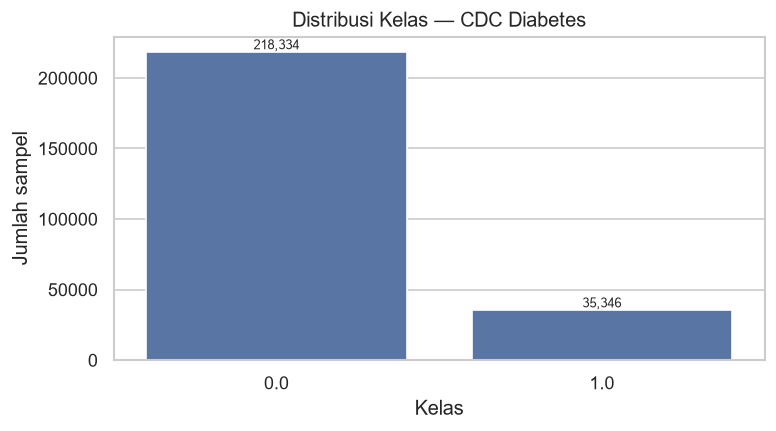

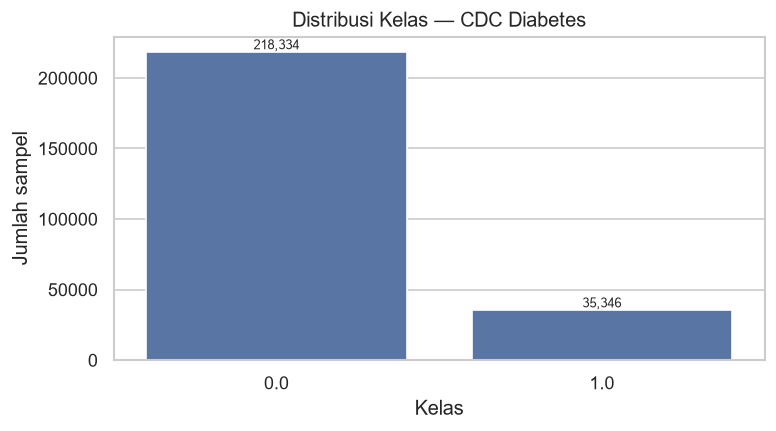

In [4]:
# Grafik distribusi kelas
utils.plot_class_distribution(
    y_bin,
    "Distribusi Kelas — CDC Diabetes",
    "dist_diabetes",
)

### Statistik Dataset Dry Bean

- **Jumlah sampel:** 13.611
- **Jumlah fitur:** 16 (setelah kolom target dipisah)
- **Missing value:** 0
- **Jumlah kelas:** 7

In [5]:
# Baca dataset dry bean dan tampilkan 5 baris pertama
df_multi = pd.read_excel(utils.DATA_PATHS["dry_bean"])

print("Shape  :", df_multi.shape)
print("Kolom  :", df_multi.shape[1])
df_multi.head()

Shape  : (13611, 17)
Kolom  : 17


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [6]:
# Pisahkan fitur dan target, lalu cek kualitas data
X_multi = df_multi.drop(columns=["Class"])
y_multi = df_multi["Class"]

print("Jumlah sampel   :", len(df_multi))
print("Jumlah fitur    :", X_multi.shape[1])
print("Missing value   :", int(df_multi.isna().sum().sum()))
print("Fitur non-angka :", list(X_multi.select_dtypes(exclude="number").columns) or "tidak ada")
print()

print("Distribusi kelas:")
print(y_multi.value_counts())
print()

print("Persentase:")
print((y_multi.value_counts(normalize=True) * 100).round(2))

Jumlah sampel   : 13611
Jumlah fitur    : 16
Missing value   : 0
Fitur non-angka : tidak ada

Distribusi kelas:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Persentase:
Class
DERMASON    26.05
SIRA        19.37
SEKER       14.89
HOROZ       14.17
CALI        11.98
BARBUNYA     9.71
BOMBAY       3.84
Name: proportion, dtype: float64


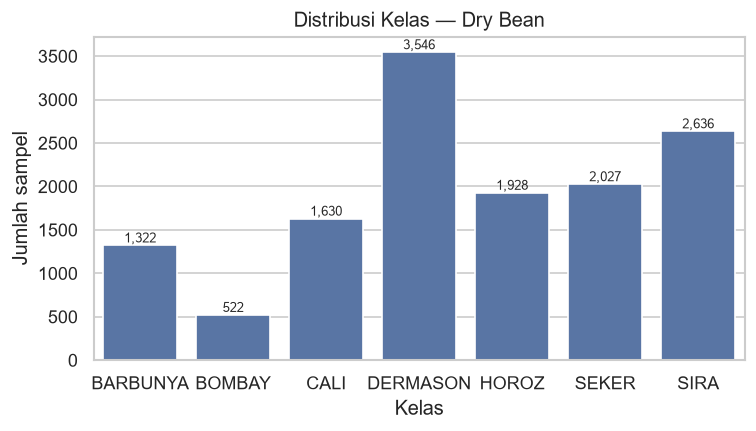

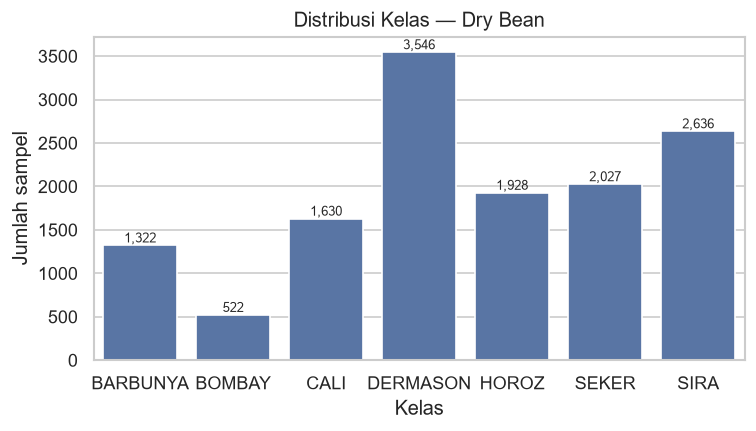

In [7]:
# Grafik distribusi kelas dry bean
utils.plot_class_distribution(
    y_multi,
    "Distribusi Kelas — Dry Bean",
    "dist_dry_bean",
)

### Preprocessing Dataset Dry Bean

Tiga langkah sebelum data masuk ke ANN:

1. **Label encoding** — kelas berupa teks (DERMASON, SIRA, ...) harus diubah
   jadi angka 0–6 karena ANN hanya bisa menghitung angka.
2. **Split 80/20** — data dibagi jadi data latih dan data uji. Memakai
   `stratify` agar proporsi tiap kelas tetap sama di kedua bagian.
3. **StandardScaler** — menyeragamkan skala fitur. Tanpa ini, fitur `Area`
   yang bernilai ~50.000 akan mendominasi fitur `ShapeFactor2` yang hanya
   ~0,001, sehingga model tidak bisa belajar dengan baik.

In [8]:
# Ubah label teks jadi angka 0-6
le = LabelEncoder()
y_encoded = le.fit_transform(y_multi)

print("Kelas asli   :", list(le.classes_))
print("Jumlah kelas :", len(le.classes_))
print("Hasil encode :", np.unique(y_encoded))

Kelas asli   : ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Jumlah kelas : 7
Hasil encode : [0 1 2 3 4 5 6]


In [9]:
# Bagi data jadi 80% latih dan 20% uji
X_train, X_test, y_train, y_test = train_test_split(
    X_multi, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded,
)

print("Data latih :", X_train.shape)
print("Data uji   :", X_test.shape)
print()
print("Jumlah per kelas di data latih :", np.bincount(y_train))
print("Jumlah per kelas di data uji   :", np.bincount(y_test))

Data latih : (10888, 16)
Data uji   : (2723, 16)

Jumlah per kelas di data latih : [1057  418 1304 2837 1542 1621 2109]
Jumlah per kelas di data uji   : [265 104 326 709 386 406 527]


In [10]:
# Seragamkan skala semua fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Sebelum scaling : min %.3f  max %.1f" % (X_train.values.min(), X_train.values.max()))
print("Sesudah scaling : min %.3f  max %.3f" % (X_train_scaled.min(), X_train_scaled.max()))

Sebelum scaling : min 0.001  max 251082.0
Sesudah scaling : min -14.467  max 6.672


### Arsitektur Model ANN Multi-class

Model dibangun dengan urutan layer:

| Layer | Neuron | Aktivasi | Fungsi |
|---|---|---|---|
| Input | 16 | — | menerima 16 fitur hasil scaling |
| Hidden 1 | 64 | ReLU | menangkap pola kombinasi fitur |
| Dropout | — | — | mencegah overfitting |
| Hidden 2 | 32 | ReLU | memadatkan pola jadi representasi kelas |
| Output | 7 | Softmax | menghasilkan probabilitas tiap kelas |

**Kenapa Softmax, bukan Sigmoid?** Softmax menghasilkan 7 angka yang totalnya
1,0 — jadi bisa dibaca sebagai probabilitas masing-masing kelas. Sigmoid hanya
cocok untuk 2 kelas.

**Kenapa loss Categorical Crossentropy?** Ini pasangan wajib Softmax untuk
kasus multi-class. Untuk binary nanti dipakai Sigmoid + Binary Crossentropy.

In [11]:
# Ubah label jadi one-hot encoding untuk 7 kelas
from tensorflow.keras.utils import to_categorical

y_train_cat = to_categorical(y_train, num_classes=7)
y_test_cat = to_categorical(y_test, num_classes=7)

print("Sebelum :", y_train[:5])
print("Sesudah :")
print(y_train_cat[:5])
print()
print("Shape train :", y_train_cat.shape)
print("Shape test  :", y_test_cat.shape)

Sebelum : [5 4 2 2 5]
Sesudah :
[[0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0.]]

Shape train : (10888, 7)
Shape test  : (2723, 7)


In [12]:
# Fungsi pembuat model ANN, dipakai untuk binary dan multiclass
from tensorflow.keras import layers, models

def build_ann(input_dim, output_dim, hidden=(64, 32), dropout=0.2,
              output_activation="softmax"):
    model = models.Sequential(name="ann")
    model.add(layers.Input(shape=(input_dim,)))

    for units in hidden:
        model.add(layers.Dense(units, activation="relu"))
        if dropout:
            model.add(layers.Dropout(dropout))

    model.add(layers.Dense(output_dim, activation=output_activation))
    return model

model_multi = build_ann(input_dim=16, output_dim=7)
model_multi.summary()

Model: "ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,399 (13.28 KB)

 Trainable params: 3,399 (13.28 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Compile dan latih model
model_multi.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
)

history_multi = model_multi.fit(
    X_train_scaled, y_train_cat,
    validation_split=0.15,
    epochs=60,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/60


  1/145 ━━━━━━━━━━━━━━━━━━━━ 2:50 1s/step - accuracy: 0.1406 - loss: 1.9981

 32/145 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3853 - loss: 1.6735 

 64/145 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5007 - loss: 1.4087

 98/145 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5682 - loss: 1.2199

133/145 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6272 - loss: 1.0735

... (242 outputs left out)

 69/145 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9293 - loss: 0.2067

103/145 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9299 - loss: 0.2012

136/145 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9287 - loss: 0.2019

145/145 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9279 - loss: 0.2046 - val_accuracy: 0.9266 - val_loss: 0.1950


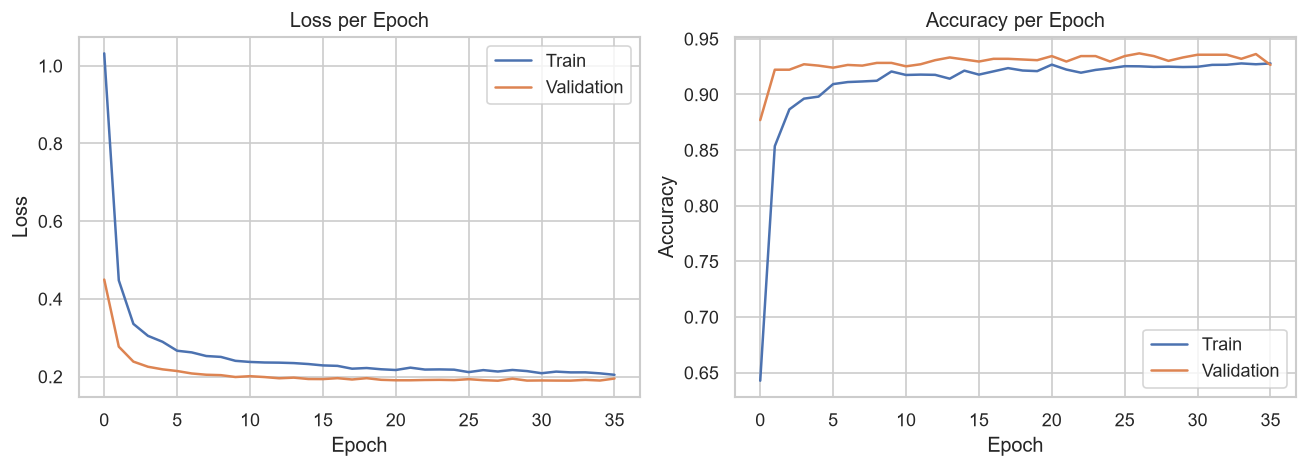

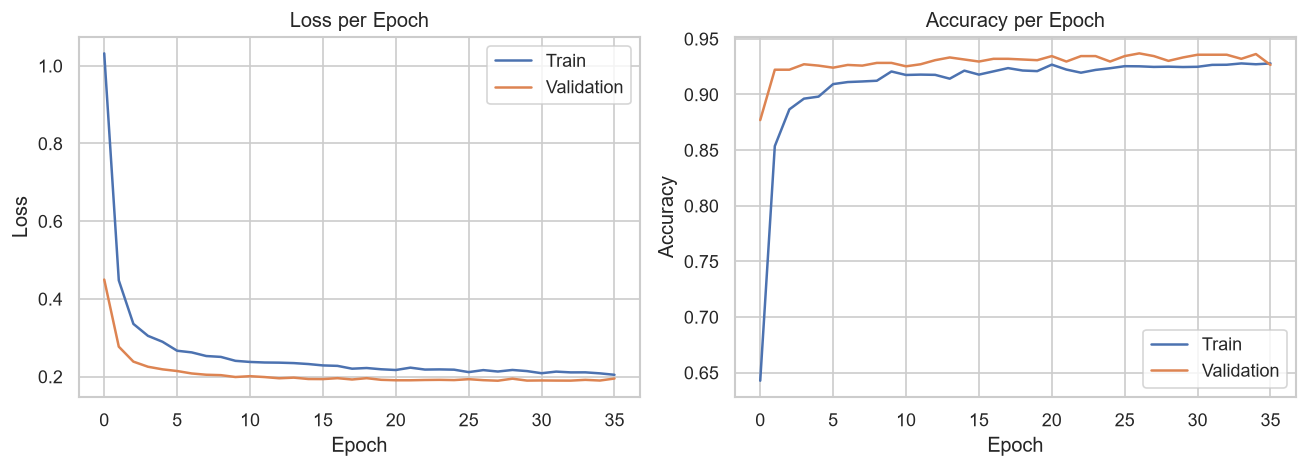

In [14]:
# Grafik loss dan accuracy per epoch
utils.plot_training_history(history_multi, "history_multi")

In [15]:
# Prediksi data uji lalu hitung metrik
y_pred_proba = model_multi.predict(X_test_scaled, verbose=0)
y_pred = np.argmax(y_pred_proba, axis=1)

metrics_multi = utils.evaluate(
    y_test, y_pred, y_pred_proba, average="macro"
)

print("Accuracy     : %.4f" % metrics_multi["accuracy"])
print("Precision    : %.4f" % metrics_multi["precision"])
print("Recall       : %.4f" % metrics_multi["recall"])
print("F1-score     : %.4f" % metrics_multi["f1"])
print("ROC-AUC OvR  : %.4f" % metrics_multi["roc_auc_ovr"])

Accuracy     : 0.9225
Precision    : 0.9370
Recall       : 0.9332
F1-score     : 0.9350
ROC-AUC OvR  : 0.9952


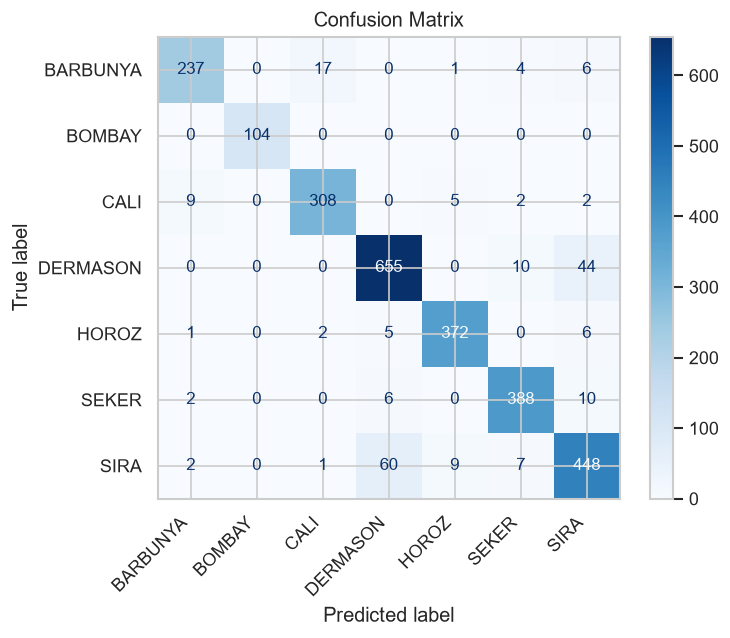

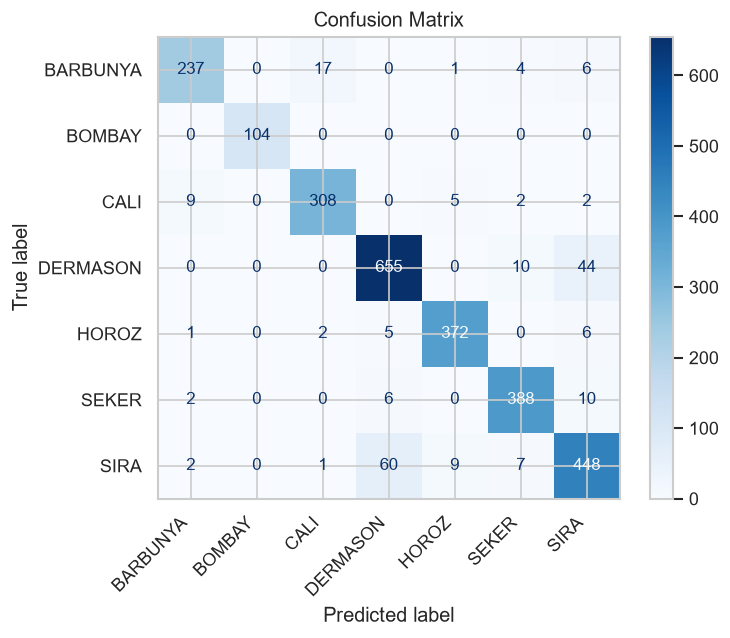

In [16]:
# Confusion matrix 7x7
utils.plot_confusion_matrix(
    y_test, y_pred,
    labels=le.classes_,
    name="cm_multi",
)

In [17]:
# Classification report per kelas
report_multi = utils.print_report(
    y_test, y_pred,
    target_names=le.classes_,
)

utils.save_metrics(metrics_multi, "metrics_multi")
print("Metrik tersimpan di output/reports/metrics_multi.json")

              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.94      0.94      0.94       326
    DERMASON       0.90      0.92      0.91       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.96      0.95       406
        SIRA       0.87      0.85      0.86       527

    accuracy                           0.92      2723
   macro avg       0.94      0.93      0.93      2723
weighted avg       0.92      0.92      0.92      2723

Metrik tersimpan di output/reports/metrics_multi.json


### Preprocessing Dataset Diabetes

Tiga langkah sebelum training:

1. **Split 80/20** — dengan `stratify` agar proporsi 86:14 tetap sama di
   data latih dan data uji.
2. **StandardScaler** — menyamakan skala fitur. `BMI` bernilai puluhan,
   sedangkan `Age` dan `GenHlth` hanya 1–13.
3. **Class weight** — memberi bobot lebih besar ke kelas minoritas
   (diabetes, 13,93%) agar model tidak mengabaikannya.

In [18]:
# Bagi data, scaling, dan hitung bobot kelas
from sklearn.utils.class_weight import compute_class_weight

X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X_bin, y_bin,
    test_size=0.2,
    random_state=42,
    stratify=y_bin,
)

scaler_bin = StandardScaler()
X_train_bin_scaled = scaler_bin.fit_transform(X_train_bin)
X_test_bin_scaled = scaler_bin.transform(X_test_bin)

print("Data latih :", X_train_bin_scaled.shape)
print("Data uji   :", X_test_bin_scaled.shape)
print()

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_bin),
    y=y_train_bin,
)
class_weight_bin = dict(enumerate(weights))
print("Bobot kelas :", class_weight_bin)

Data latih : (202944, 21)
Data uji   : (50736, 21)

Bobot kelas : {0: np.float64(0.5809454562109614), 1: np.float64(3.5884994872157585)}


In [19]:
# Bangun model binary: 1 neuron output, aktivasi sigmoid
model_bin = build_ann(
    input_dim=21,
    output_dim=1,
    output_activation="sigmoid",
)
model_bin.summary()

Model: "ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,521 (13.75 KB)

 Trainable params: 3,521 (13.75 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Compile dan latih model binary
model_bin.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

early_stop_bin = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

history_bin = model_bin.fit(
    X_train_bin_scaled, y_train_bin,
    validation_split=0.15,
    epochs=40,
    batch_size=256,
    class_weight=class_weight_bin,
    callbacks=[early_stop_bin],
    verbose=1,
)

Epoch 1/40


  1/674 ━━━━━━━━━━━━━━━━━━━━ 12:54 1s/step - accuracy: 0.6094 - loss: 0.7052

 25/674 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6320 - loss: 0.6385  

 50/674 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6649 - loss: 0.5981

 76/674 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6792 - loss: 0.5814

103/674 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6859 - loss: 0.5672

... (200 outputs left out)

591/674 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7124 - loss: 0.5060

620/674 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7124 - loss: 0.5056

648/674 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7128 - loss: 0.5050

674/674 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7126 - loss: 0.5056 - val_accuracy: 0.7105 - val_loss: 0.5204


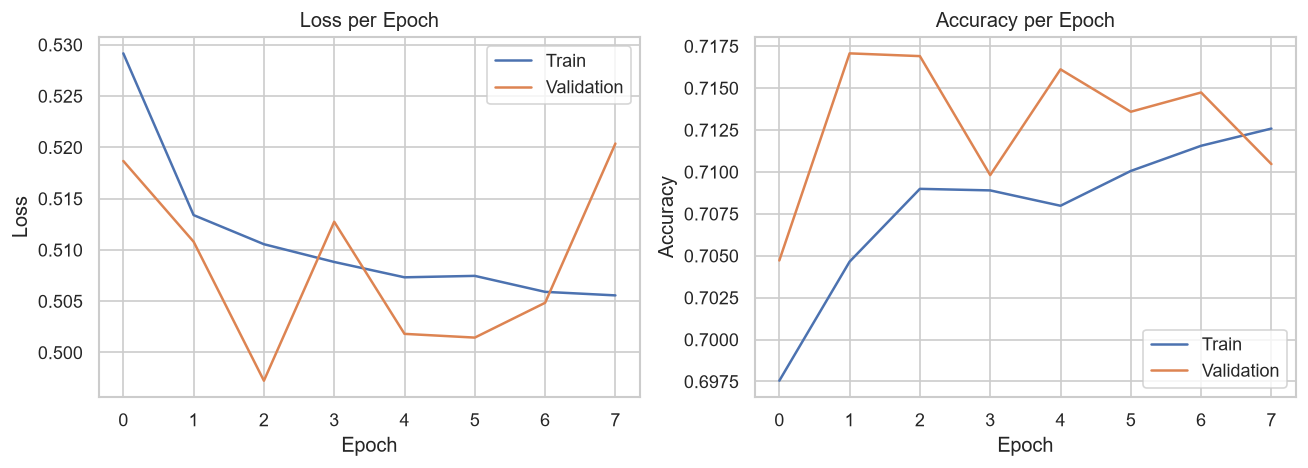

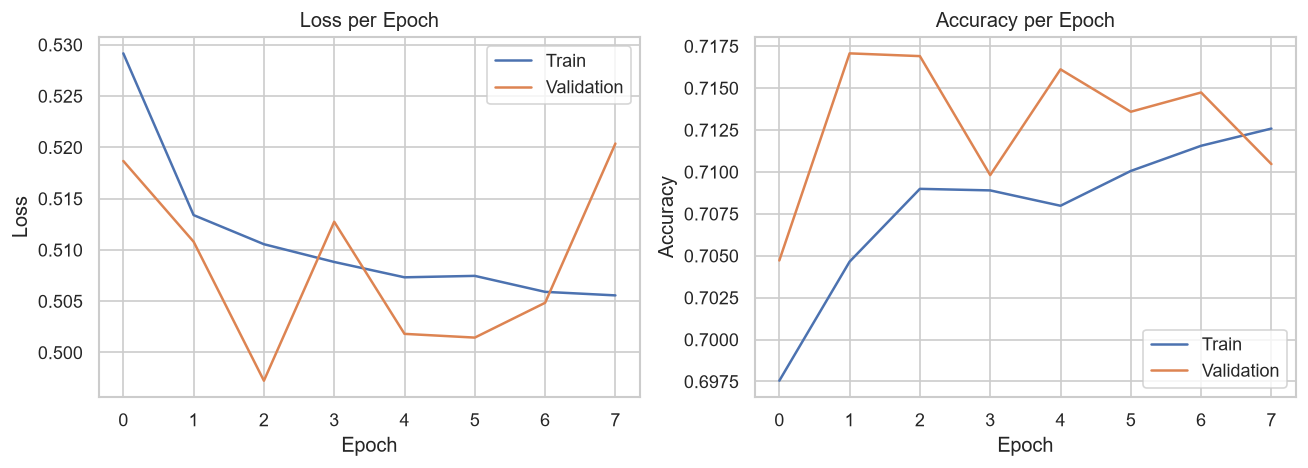

In [21]:
# Grafik loss dan accuracy model binary
utils.plot_training_history(history_bin, "history_bin")

### Catatan Hasil Training Binary

Akurasi training hanya sekitar 0,71 — jauh di bawah 0,86 yang bisa dicapai
model "malas" yang selalu menebak kelas mayoritas. Ini disengaja.

Dengan `class_weight` balanced, kesalahan pada kelas minoritas (diabetes)
diberi bobot sekitar 6 kali lebih besar. Model jadi terdorong untuk mendeteksi
diabetes, dengan konsekuensi lebih banyak pasien sehat yang salah
diklasifikasikan sebagai diabetes (false positive).

Untuk skrining medis, trade-off ini dapat diterima: lebih baik melakukan
pemeriksaan lanjutan pada orang sehat daripada melewatkan penderita diabetes.

In [22]:
# Prediksi data uji dan hitung metrik
y_pred_proba_bin = model_bin.predict(X_test_bin_scaled, verbose=0).ravel()
y_pred_bin = (y_pred_proba_bin >= 0.5).astype(int)

metrics_bin = utils.evaluate(
    y_test_bin, y_pred_bin, y_pred_proba_bin, average="binary"
)

print("Accuracy     : %.4f" % metrics_bin["accuracy"])
print("Precision    : %.4f" % metrics_bin["precision"])
print("Recall       : %.4f" % metrics_bin["recall"])
print("F1-score     : %.4f" % metrics_bin["f1"])
print("ROC-AUC      : %.4f" % metrics_bin["roc_auc"])

Accuracy     : 0.7133
Precision    : 0.3014
Recall       : 0.8025
F1-score     : 0.4382
ROC-AUC      : 0.8249


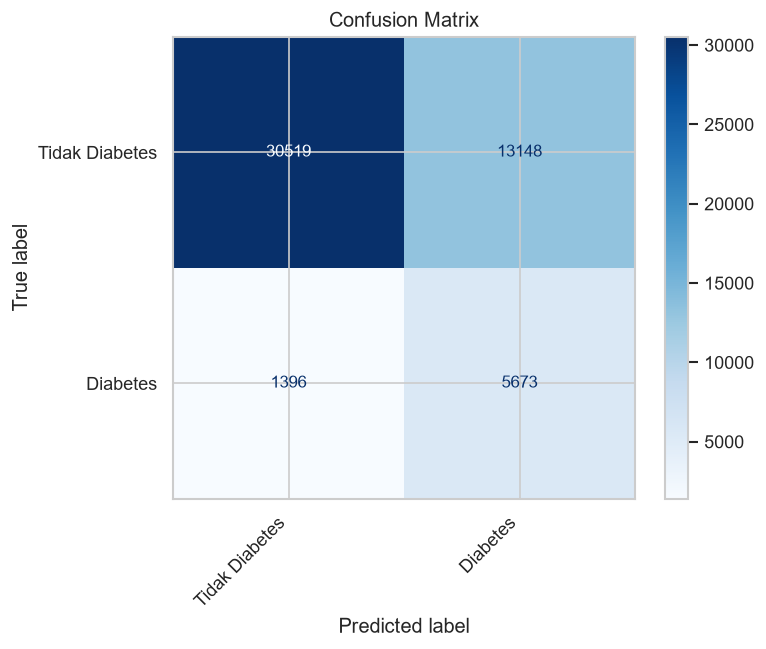

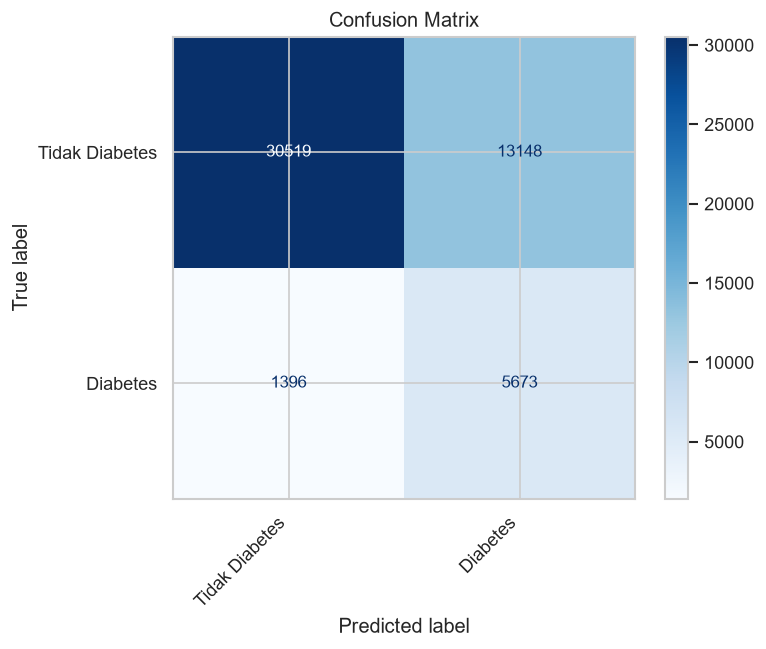

In [23]:
# Confusion matrix binary
utils.plot_confusion_matrix(
    y_test_bin, y_pred_bin,
    labels=["Tidak Diabetes", "Diabetes"],
    name="cm_binary",
)

In [24]:
# Classification report dan simpan hasil
report_bin = utils.print_report(
    y_test_bin, y_pred_bin,
    target_names=["Tidak Diabetes", "Diabetes"],
)

utils.save_metrics(metrics_bin, "metrics_binary")
print("Metrik tersimpan di output/reports/metrics_binary.json")

                precision    recall  f1-score   support

Tidak Diabetes       0.96      0.70      0.81     43667
      Diabetes       0.30      0.80      0.44      7069

      accuracy                           0.71     50736
     macro avg       0.63      0.75      0.62     50736
  weighted avg       0.87      0.71      0.76     50736

Metrik tersimpan di output/reports/metrics_binary.json


In [25]:
# Latih model pembanding tanpa class weight
model_base = build_ann(input_dim=21, output_dim=1, output_activation="sigmoid")

model_base.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

history_base = model_base.fit(
    X_train_bin_scaled, y_train_bin,
    validation_split=0.15,
    epochs=40,
    batch_size=256,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True)],
    verbose=0,
)

y_proba_base = model_base.predict(X_test_bin_scaled, verbose=0).ravel()
y_pred_base = (y_proba_base >= 0.5).astype(int)
metrics_base = utils.evaluate(y_test_bin, y_pred_base, y_proba_base, average="binary")

print("TANPA class weight")
print("  Accuracy : %.4f" % metrics_base["accuracy"])
print("  Recall   : %.4f" % metrics_base["recall"])
print("  F1       : %.4f" % metrics_base["f1"])
print()
print("DENGAN class weight")
print("  Accuracy : %.4f" % metrics_bin["accuracy"])
print("  Recall   : %.4f" % metrics_bin["recall"])
print("  F1       : %.4f" % metrics_bin["f1"])

TANPA class weight
  Accuracy : 0.8649
  Recall   : 0.1508
  F1       : 0.2372

DENGAN class weight
  Accuracy : 0.7133
  Recall   : 0.8025
  F1       : 0.4382


           Skenario  Accuracy  Recall     F1
 Tanpa class weight    0.8649  0.1508 0.2372
Dengan class weight    0.7133  0.8025 0.4382


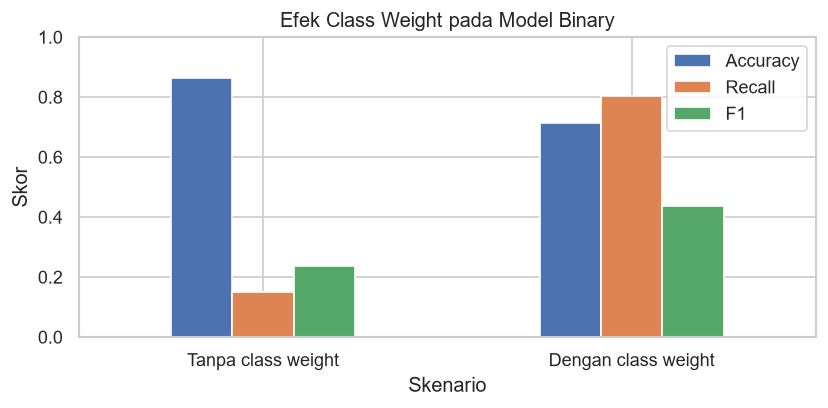

In [26]:
%matplotlib inline
# Tabel perbandingan efek class weight
banding = pd.DataFrame([
    {"Skenario": "Tanpa class weight", "Accuracy": metrics_base["accuracy"],
     "Recall": metrics_base["recall"], "F1": metrics_base["f1"]},
    {"Skenario": "Dengan class weight", "Accuracy": metrics_bin["accuracy"],
     "Recall": metrics_bin["recall"], "F1": metrics_bin["f1"]},
]).round(4)

print(banding.to_string(index=False))

ax = banding.set_index("Skenario")[["Accuracy", "Recall", "F1"]].plot(
    kind="bar", figsize=(7, 3.5), rot=0)
ax.set_ylabel("Skor")
ax.set_title("Efek Class Weight pada Model Binary")
ax.set_ylim(0, 1)
plt.tight_layout()
utils.save_fig("perbandingan_class_weight")
plt.show()

In [27]:
# Simpan model dan scaler ke folder output/models
model_multi.save(utils.MODELS_DIR / "ann_multi.keras")
model_bin.save(utils.MODELS_DIR / "ann_binary.keras")

import joblib
joblib.dump(scaler, utils.MODELS_DIR / "scaler_multi.pkl")
joblib.dump(scaler_bin, utils.MODELS_DIR / "scaler_binary.pkl")

print("Model dan scaler tersimpan di:", utils.MODELS_DIR)

Model dan scaler tersimpan di: C:\Knowledge\Intelegensi Buatan\Model Klasifikasi Binary & Multiclass\output\models


In [28]:
# Muat ulang model dan cek hasilnya sama
import tensorflow as tf

model_cek = tf.keras.models.load_model(utils.MODELS_DIR / "ann_binary.keras")
y_cek = (model_cek.predict(X_test_bin_scaled, verbose=0).ravel() >= 0.5).astype(int)

print("Akurasi model asli     : %.4f" % metrics_bin["accuracy"])
print("Akurasi model dimuat   : %.4f" % (y_cek == y_test_bin).mean())
print("Prediksi identik       :", bool((y_cek == y_pred_bin).all()))

Akurasi model asli     : 0.7133
Akurasi model dimuat   : 0.7133
Prediksi identik       : True


In [29]:
# Muat model dan scaler, lalu prediksi satu pasien baru
model_dipakai = tf.keras.models.load_model(utils.MODELS_DIR / "ann_binary.keras")
scaler_dipakai = joblib.load(utils.MODELS_DIR / "scaler_binary.pkl")

# ambil 1 baris data uji sebagai contoh
pasien = X_test_bin.iloc[[0]]

pasien_scaled = scaler_dipakai.transform(pasien)
probabilitas = model_dipakai.predict(pasien_scaled, verbose=0).ravel()[0]

print("Probabilitas diabetes : %.2f%%" % (probabilitas * 100))
print("Hasil prediksi        :", "DIABETES" if probabilitas >= 0.5 else "TIDAK DIABETES")
print("Jawaban sebenarnya    :", "DIABETES" if y_test_bin.iloc[0] == 1 else "TIDAK DIABETES")

Probabilitas diabetes : 50.86%
Hasil prediksi        : DIABETES
Jawaban sebenarnya    : TIDAK DIABETES


In [30]:
# Prediksi data pasien baru (urutan kolom harus sama dengan X_bin)
pasien_baru = pd.DataFrame([{
    "HighBP": 1, "HighChol": 1, "CholCheck": 1, "BMI": 32,
    "Smoker": 0, "Stroke": 0, "HeartDiseaseorAttack": 0,
    "PhysActivity": 1, "Fruits": 1, "Veggies": 1,
    "HvyAlcoholConsump": 0, "AnyHealthcare": 1, "NoDocbcCost": 0,
    "GenHlth": 4, "MentHlth": 0, "PhysHlth": 0, "DiffWalk": 0,
    "Sex": 1, "Age": 9, "Education": 5, "Income": 6,
}])

skor = scaler_dipakai.transform(pasien_baru)
p = model_dipakai.predict(skor, verbose=0).ravel()[0]

print("Probabilitas diabetes : %.2f%%" % (p * 100))
print("Hasil prediksi        :", "DIABETES" if p >= 0.5 else "TIDAK DIABETES")

Probabilitas diabetes : 83.11%
Hasil prediksi        : DIABETES


In [31]:
# Prediksi satu sampel kacang
model_kacang = tf.keras.models.load_model(utils.MODELS_DIR / "ann_multi.keras")
scaler_kacang = joblib.load(utils.MODELS_DIR / "scaler_multi.pkl")

sampel = X_multi.iloc[[0]]
sampel_scaled = scaler_kacang.transform(sampel)
proba = model_kacang.predict(sampel_scaled, verbose=0)[0]

kelas = le.classes_[np.argmax(proba)]
print("Probabilitas tiap kelas:")
for nama, nilai in zip(le.classes_, proba):
    print("  %-10s %.4f" % (nama, nilai))
print()
print("Prediksi    :", kelas)
print("Sebenarnya  :", y_multi.iloc[0])

Probabilitas tiap kelas:
  BARBUNYA   0.0000
  BOMBAY     0.0000
  CALI       0.0000
  DERMASON   0.1747
  HOROZ      0.0000
  SEKER      0.8252
  SIRA       0.0001

Prediksi    : SEKER
Sebenarnya  : SEKER


In [32]:
# Bandingkan beberapa arsitektur ANN pada dataset dry bean
hasil_arsitektur = []

for nama, hidden in [("64-32", (64, 32)), ("128-64", (128, 64)), ("128-64-32", (128, 64, 32))]:
    m = build_ann(input_dim=16, output_dim=7, hidden=hidden)
    m.compile(optimizer=tf.keras.optimizers.Adam(0.001),
              loss="categorical_crossentropy", metrics=["accuracy"])
    m.fit(X_train_scaled, y_train_cat,
          validation_split=0.15, epochs=60, batch_size=64,
          callbacks=[tf.keras.callbacks.EarlyStopping(
              monitor="val_loss", patience=8, restore_best_weights=True)],
          verbose=0)

    pred = np.argmax(m.predict(X_test_scaled, verbose=0), axis=1)
    akurasi = (pred == y_test).mean()
    hasil_arsitektur.append({"Arsitektur": nama, "Accuracy": round(akurasi, 4)})
    print("%-12s accuracy = %.4f" % (nama, akurasi))

pd.DataFrame(hasil_arsitektur)

64-32        accuracy = 0.9251


128-64       accuracy = 0.9273


128-64-32    accuracy = 0.9218


,Arsitektur,Accuracy
0,64-32,0.9251
1,128-64,0.9273
2,128-64-32,0.9218


In [33]:
# Cari threshold terbaik memakai data validasi (bukan data uji)
from sklearn.metrics import f1_score

n_val = int(len(X_train_bin_scaled) * 0.15)
X_val = X_train_bin_scaled[-n_val:]
y_val = y_train_bin[-n_val:]

proba_val = model_bin.predict(X_val, verbose=0).ravel()

skor = []
for th in np.arange(0.30, 0.81, 0.05):
    pred_th = (proba_val >= th).astype(int)
    skor.append({"threshold": round(float(th), 2),
                 "accuracy": round(float((pred_th == y_val).mean()), 4),
                 "f1": round(float(f1_score(y_val, pred_th)), 4)})

tabel_th = pd.DataFrame(skor)
print(tabel_th.to_string(index=False))
print()
print("Threshold terbaik menurut F1:", tabel_th.loc[tabel_th["f1"].idxmax(), "threshold"])

 threshold  accuracy     f1
      0.30    0.5776 0.3771
      0.35    0.6107 0.3917
      0.40    0.6446 0.4061
      0.45    0.6806 0.4234
      0.50    0.7169 0.4408
      0.55    0.7514 0.4545
      0.60    0.7858 0.4672
      0.65    0.8141 0.4698
      0.70    0.8389 0.4594
      0.75    0.8549 0.4140
      0.80    0.8649 0.3307

Threshold terbaik menurut F1: 0.65


In [34]:
# Bandingkan hasil pada data uji: threshold 0.5 vs threshold terbaik
threshold_terbaik = 0.60

pred_baru = (y_pred_proba_bin >= threshold_terbaik).astype(int)
metrics_baru = utils.evaluate(y_test_bin, pred_baru, y_pred_proba_bin, average="binary")

banding_th = pd.DataFrame([
    {"Threshold": 0.5, "Accuracy": metrics_bin["accuracy"],
     "Recall": metrics_bin["recall"], "Precision": metrics_bin["precision"],
     "F1": metrics_bin["f1"]},
    {"Threshold": threshold_terbaik, "Accuracy": metrics_baru["accuracy"],
     "Recall": metrics_baru["recall"], "Precision": metrics_baru["precision"],
     "F1": metrics_baru["f1"]},
]).round(4)

print(banding_th.to_string(index=False))
utils.save_metrics(metrics_baru, "metrics_binary_threshold")

 Threshold  Accuracy  Recall  Precision     F1
       0.5    0.7133  0.8025     0.3014 0.4382
       0.6    0.7824  0.6719     0.3526 0.4625


WindowsPath('C:/Knowledge/Intelegensi Buatan/Model Klasifikasi Binary & Multiclass/output/reports/metrics_binary_threshold.json')